<a href="https://colab.research.google.com/github/sunjidaakter-saj/wholesale-customer/blob/main/wholesale_customer_p.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from sklearn.cluster import DBSCAN,KMeans
from sklearn.preprocessing import StandardScaler

In [ ]:
df = pd.read_csv("Wholesale Customers data.csv")
df.head()

,Channel,Region,Fresh,Milk,Grocery,Frozen,Detergents_Paper,Delicassen
0,2,3,12669,9656,7561,214,2674,1338
1,2,3,7057,9810,9568,1762,3293,1776
2,2,3,6353,8808,7684,2405,3516,7844
3,1,3,13265,1196,4221,6404,507,1788
4,2,3,22615,5410,7198,3915,1777,5185


In [ ]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 440 entries, 0 to 439
Data columns (total 8 columns):
 #   Column            Non-Null Count  Dtype
---  ------            --------------  -----
 0   Channel           440 non-null    int64
 1   Region            440 non-null    int64
 2   Fresh             440 non-null    int64
 3   Milk              440 non-null    int64
 4   Grocery           440 non-null    int64
 5   Frozen            440 non-null    int64
 6   Detergents_Paper  440 non-null    int64
 7   Delicassen        440 non-null    int64
dtypes: int64(8)
memory usage: 27.6 KB


In [ ]:
df.describe()

,Channel,Region,Fresh,Milk,Grocery,Frozen,Detergents_Paper,Delicassen
count,440.000000,440.000000,440.000000,440.000000,440.000000,440.000000,440.000000,440.000000
mean,1.322727,2.543182,12000.297727,5796.265909,7951.277273,3071.931818,2881.493182,1524.870455
std,0.468052,0.774272,12647.328865,7380.377175,9503.162829,4854.673333,4767.854448,2820.105937
min,1.000000,1.000000,3.000000,55.000000,3.000000,25.000000,3.000000,3.000000
25%,1.000000,2.000000,3127.750000,1533.000000,2153.000000,742.250000,256.750000,408.250000
50%,1.000000,3.000000,8504.000000,3627.000000,4755.500000,1526.000000,816.500000,965.500000
75%,2.000000,3.000000,16933.750000,7190.250000,10655.750000,3554.250000,3922.000000,1820.250000
max,2.000000,3.000000,112151.000000,73498.000000,92780.000000,60869.000000,40827.000000,47943.000000


In [ ]:
df.isnull().sum()

Channel             0
Region              0
Fresh               0
Milk                0
Grocery             0
Frozen              0
Detergents_Paper    0
Delicassen          0
dtype: int64

In [ ]:
scaler = StandardScaler()
scaled_data = scaler.fit_transform(df)

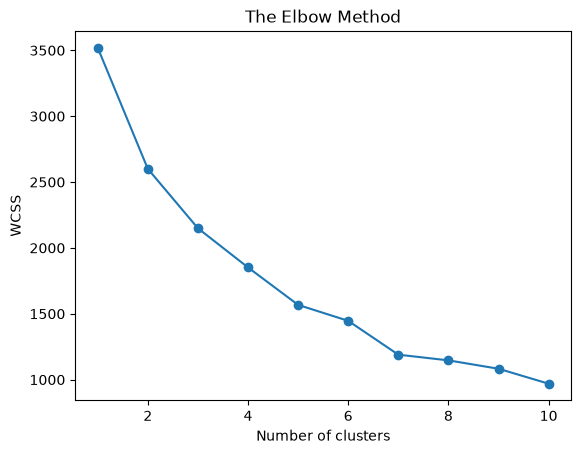

In [ ]:
wcss = []
for i in range(1,11):
    kmeans = KMeans(n_clusters=i,init='k-means++',random_state=42)
    kmeans.fit(scaled_data)
    wcss.append(kmeans.inertia_)
plt.plot(range(1,11),wcss,marker='o')
plt.title('The Elbow Method')
plt.xlabel('Number of clusters')
plt.ylabel('WCSS')
plt.show()

In [ ]:
kmeans = KMeans(n_clusters=3,init='k-means++',random_state=42)
y_kmeans = kmeans.fit_predict(scaled_data)
df['Cluster'] = y_kmeans
df.head()

,Channel,Region,Fresh,Milk,Grocery,Frozen,Detergents_Paper,Delicassen,Cluster
0,2,3,12669,9656,7561,214,2674,1338,0
1,2,3,7057,9810,9568,1762,3293,1776,0
2,2,3,6353,8808,7684,2405,3516,7844,0
3,1,3,13265,1196,4221,6404,507,1788,1
4,2,3,22615,5410,7198,3915,1777,5185,0


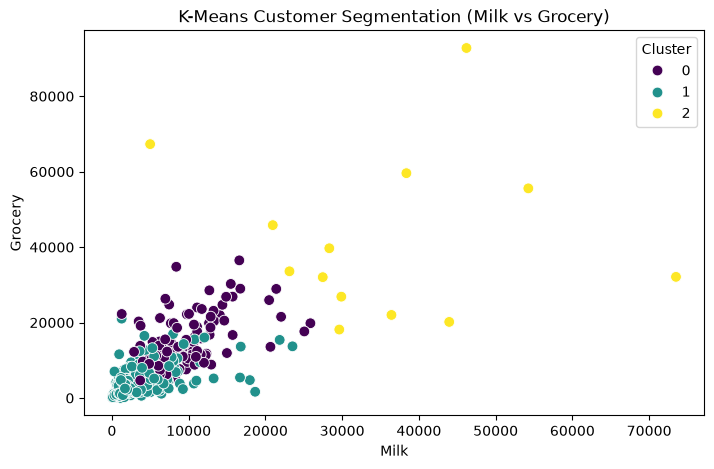

In [ ]:
plt.figure(figsize=(8, 5))
sns.scatterplot(
    x=df['Milk'], y=df['Grocery'], hue=df['Cluster'], palette='viridis', s=60
)
plt.title('K-Means Customer Segmentation (Milk vs Grocery)')
plt.xlabel('Milk')
plt.ylabel('Grocery')
plt.show()

In [ ]:
from sklearn.cluster import DBSCAN

dbscan = DBSCAN(eps=1.5, min_samples=5)
y_dbscan = dbscan.fit_predict(scaled_data)

df['DBSCAN_Cluster'] = y_dbscan

print(df['DBSCAN_Cluster'].value_counts())

DBSCAN_Cluster
 1    277
 0    119
-1     44
Name: count, dtype: int64


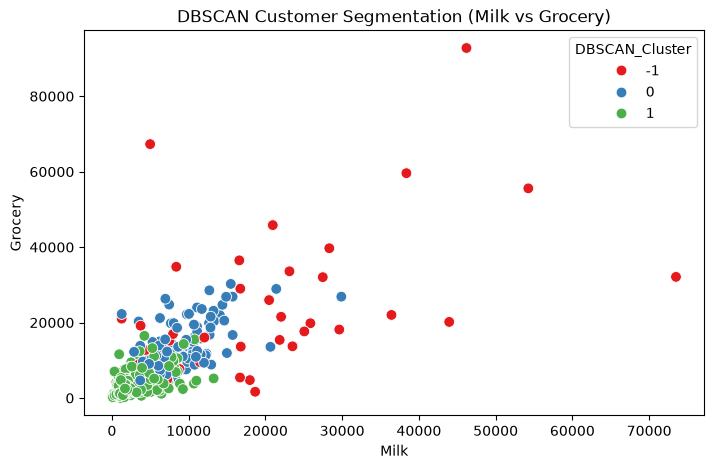

In [ ]:
plt.figure(figsize=(8, 5))
sns.scatterplot(
    x=df['Milk'],
    y=df['Grocery'],
    hue=df['DBSCAN_Cluster'],
    palette='Set1',
    s=60,
)
plt.title('DBSCAN Customer Segmentation (Milk vs Grocery)')
plt.xlabel('Milk')
plt.ylabel('Grocery')
plt.show()

In [ ]:
from sklearn.metrics import silhouette_score

kmeans_score = silhouette_score(scaled_data, df['Cluster'])
dbscan_score = silhouette_score(scaled_data, df['DBSCAN_Cluster'])

print(f'K-Means Silhouette Score: {kmeans_score:.3f}')
print(f'DBSCAN Silhouette Score: {dbscan_score:.3f}')

K-Means Silhouette Score: 0.357
DBSCAN Silhouette Score: 0.343


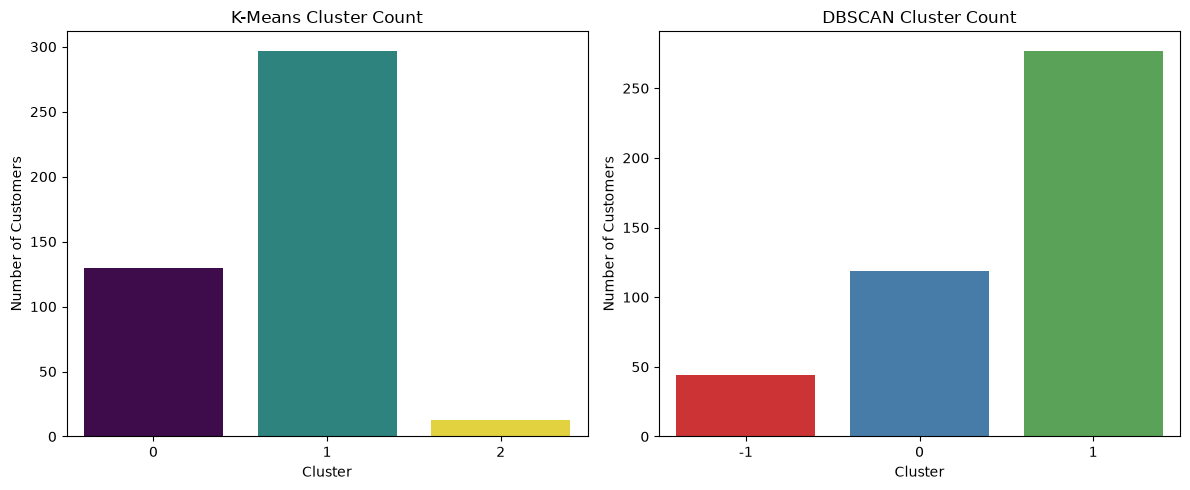

In [ ]:
plt.figure(figsize=(12, 5))

plt.subplot(1, 2, 1)
sns.countplot(
    x='Cluster', data=df, hue='Cluster', palette='viridis', legend=False
)
plt.title('K-Means Cluster Count')
plt.xlabel('Cluster')
plt.ylabel('Number of Customers')

plt.subplot(1, 2, 2)
sns.countplot(
    x='DBSCAN_Cluster',
    data=df,
    hue='DBSCAN_Cluster',
    palette='Set1',
    legend=False,
)
plt.title('DBSCAN Cluster Count')
plt.xlabel('Cluster')
plt.ylabel('Number of Customers')

plt.tight_layout()
plt.show()

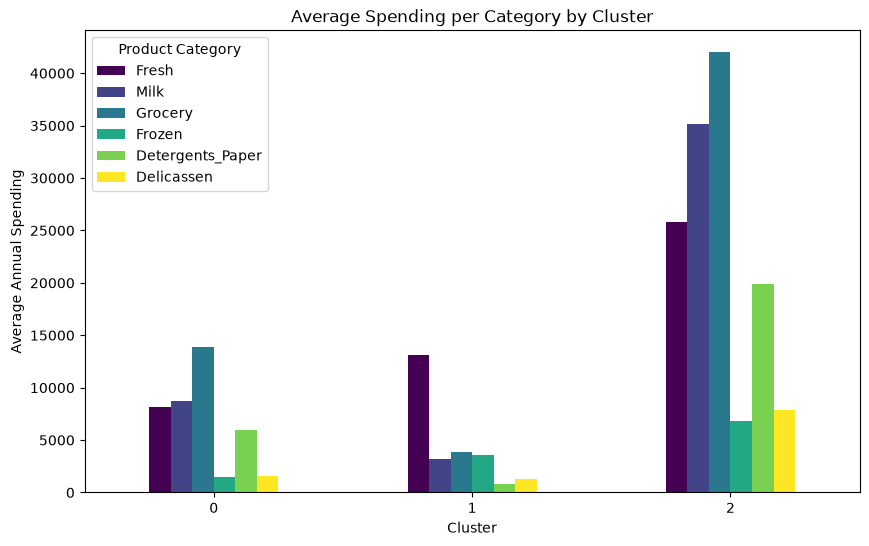

In [ ]:
cluster_means = df.groupby('Cluster')[
    ['Fresh', 'Milk', 'Grocery', 'Frozen', 'Detergents_Paper', 'Delicassen']
].mean()

cluster_means.plot(kind='bar', figsize=(10, 6), colormap='viridis')
plt.title('Average Spending per Category by Cluster')
plt.xlabel('Cluster')
plt.ylabel('Average Annual Spending')
plt.xticks(rotation=0)
plt.legend(title='Product Category')
plt.show()

In [ ]:
cluster_summary = df.groupby('Cluster').mean()
print(cluster_summary)

          Channel    Region         Fresh          Milk       Grocery  \
Cluster                                                                 
0        2.000000  2.623077   8165.915385   8748.515385  13905.492308   
1        1.003367  2.505051  13075.898990   3218.737374   3855.696970   
2        1.846154  2.615385  25770.769231  35160.384615  41977.384615   

              Frozen  Detergents_Paper   Delicassen  DBSCAN_Cluster  
Cluster                                                              
0        1441.630769       5991.146154  1535.007692       -0.092308  
1        3620.400673        776.875421  1242.249158        0.865320  
2        6844.538462      19867.384615  7880.307692       -0.923077  


In [ ]:
df.to_csv('wholesale_segmented_result.csv', index=False)
print('File saved successfully!')

File saved successfully!
